In [1]:
!pip install python-louvain networkx scikit-learn seaborn matplotlib tqdm -q

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from tqdm.auto import tqdm

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform
from numpy.linalg import norm
import networkx as nx
from scipy.ndimage import rotate as ndimage_rotate

import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({'figure.dpi': 120, 'font.size': 10})
print("loaded;")

loaded;


In [2]:
!pip uninstall community -y
!pip uninstall python-louvain -y
!pip install python-louvain

import subprocess, sys

def pip_install(pkg):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

try:
    import community as community_louvain
except ImportError:
    pip_install("python-louvain")
    import community as community_louvain
print(dir(community_louvain))
try:
    import networkx
except ImportError:
    pip_install("networkx")

print("gut!!")


Found existing installation: community 1.0.0b1
Uninstalling community-1.0.0b1:
  Successfully uninstalled community-1.0.0b1
Found existing installation: python-louvain 0.16
Uninstalling python-louvain-0.16:
  Successfully uninstalled python-louvain-0.16
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 204.6/204.6 kB 4.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for python-louvain: filename=python_louvain-0.16-py3-none-any.whl size=9388 sha256=cf862e88a1f578e6eb85c590186226d6fc1e56f151977bca953db6b1216a8f19
  Stored in directory: /root/.cache/pip/wheels/40/f1/e3/485b698c520fa0baee1d07897abc7b8d6479b7d199ce96f4af
Successfully built python-louvain
['__author__', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__path__', '__spec__', '__version__', 'best_partition', 'community_louvain', 'community_status', 'generate_dendrogram', 'induced_graph', 'load_binary', 'modularity', 'partition_at_level']
Wszystkie biblioteki 

In [3]:
#idk why but sometimes its important to install louvain again
import subprocess, sys

def pip_install(pkg):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

try:
    import community as community_louvain
    _ = community_louvain.best_partition
except (ImportError, AttributeError):
    pip_install("python-louvain")
    import community as community_louvain

print("community_louvain :", hasattr(community_louvain, 'best_partition'))

community_louvain : True


In [4]:
try:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
    print("Drive - done")
except Exception:
    print("not works")

Mounted at /content/drive
Drive - done


## settingss


In [5]:
INPUT_DIR = '/content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/new_proteins_1805'
ROI_RADIUS  = 25
GRID_SIZE   = 5
MAP_HEIGHT  = 90
MAP_WIDTH   = 180
SHIFTS      = 180      # 180 angles =  rot  by 2deg
ANGLE_STEP  = 360.0 / SHIFTS   # step by  2deg

# weight argument magnitude in  final similarity (0–1)
MAGNITUDE_WEIGHT = 0.35

# min threshold in creating branches in graph
GRAPH_SIM_THRESHOLD = 0.50

def get_full_circle_mask(h=MAP_HEIGHT, w=MAP_WIDTH, radius=ROI_RADIUS):
    cy, cx = h // 2, w // 2
    yy, xx = np.ogrid[:h, :w]
    return ((xx - cx)**2 + (yy - cy)**2) <= radius**2

circle_mask = get_full_circle_mask()   # shape (MAP_HEIGHT, MAP_WIDTH)


def get_grid_masks_patch(radius=ROI_RADIUS, grid_size=GRID_SIZE):
    ph = pw = 2 * radius
    cy, cx = ph // 2, pw // 2
    yy, xx = np.ogrid[:ph, :pw]
    patch_circle_mask = ((xx - cx)**2 + (yy - cy)**2) <= radius**2

    cell_h = ph / grid_size
    cell_w = pw / grid_size

    valid_masks = []
    for i in range(grid_size):
        for j in range(grid_size):
            r_start = int(i * cell_h)
            r_end   = int((i + 1) * cell_h)
            c_start = int(j * cell_w)
            c_end   = int((j + 1) * cell_w)
            cell_mask = np.zeros((ph, pw), dtype=bool)
            cell_mask[r_start:r_end, c_start:c_end] = True
            valid_masks.append(cell_mask & patch_circle_mask)

    return valid_masks, patch_circle_mask


def extract_roi_patch(m, radius=ROI_RADIUS, h=MAP_HEIGHT, w=MAP_WIDTH):
    cy, cx = h // 2, w // 2
    y0, y1 = max(0, cy - radius), min(h, cy + radius)
    x0, x1 = max(0, cx - radius), min(w, cx + radius)
    return m[y0:y1, x0:x1].copy().astype(float)


def extract_map_features(patch, patch_valid_masks, patch_circle_mask):
    roi_vals = patch[patch_circle_mask]
    global_mean     = np.mean(roi_vals)
    global_std      = np.std(roi_vals)
    global_mean_abs = np.mean(np.abs(roi_vals))

    features = []
    for mask in patch_valid_masks:
        v = patch[mask]
        if len(v) > 0:
            features.extend([
                np.mean(v),
                np.std(v),
                np.sum(v > 0) / len(v),
                np.sum(v < 0) / len(v),
                np.mean(np.abs(v))
            ])
        else:
            features.extend([0, 0, 0, 0, 0])

    features.extend([global_mean, global_std, global_mean_abs])
    return np.array(features, dtype=np.float32)


patch_valid_masks, patch_circle_mask = get_grid_masks_patch()
V_FEATS = len(patch_valid_masks) * 5 + 3   # +3 global features
print(f"cells inside ROI (patches): {len(patch_valid_masks)}")
print(f"features vector size: {V_FEATS}")
print(f"size ROI: {2*ROI_RADIUS}×{2*ROI_RADIUS}px, rot step: {ANGLE_STEP}deg")


cells inside ROI (patches): 25
features vector size: 128
size ROI: 50×50px, rot step: 2.0deg


In [6]:
npy_files = sorted(glob.glob(os.path.join(INPUT_DIR, '*.npy')))
N = len(npy_files)
map_names = [os.path.basename(f).replace('.npy', '') for f in npy_files]
print(f" {N} .npy files")

A_raw = np.zeros((N, V_FEATS), dtype=np.float32)
B_raw = np.zeros((N, SHIFTS, V_FEATS), dtype=np.float32)

all_roi_stds = []
for fpath in npy_files:
    m = np.load(fpath)
    all_roi_stds.append(np.std(m[circle_mask]))
dataset_std_median = np.median(all_roi_stds)
print(f"median in dataset: {dataset_std_median:.4f}")

for i, fpath in enumerate(tqdm(npy_files, desc="loading  maps and rotations>>>")):
    m = np.load(fpath)

    # extract patch
    patch = extract_roi_patch(m)

    # base features (without rot, shift=0 =>angle=0deg)
    A_raw[i] = extract_map_features(patch, patch_valid_masks, patch_circle_mask)

    # features foreach rot => rot PATCH
    for shift in range(SHIFTS):
        angle = shift * ANGLE_STEP #shift=1 => 2deg, shift=90 = 180deg
        if angle == 0:
            patch_rot = patch
        else:
            patch_rot = ndimage_rotate(patch, angle, reshape=False,
                                       mode='nearest', order=1)
        B_raw[i, shift] = extract_map_features(patch_rot, patch_valid_masks, patch_circle_mask)

print("done.")


 42 .npy files
median in dataset: 0.3148


loading  maps and rotations>>>:   0%|          | 0/42 [00:00<?, ?it/s]

done.


## ROI visualization


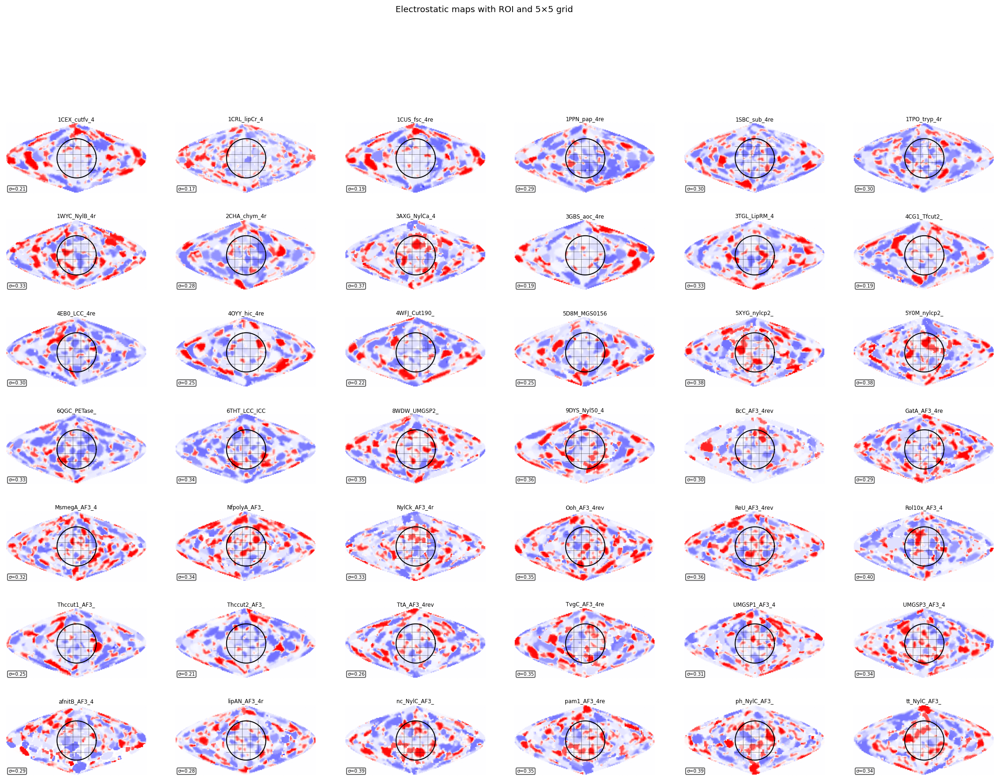

In [7]:
def plot_all_maps_with_roi(npy_files, map_names, circle_mask,
                            roi_radius=ROI_RADIUS, grid_size=GRID_SIZE,
                            h=MAP_HEIGHT, w=MAP_WIDTH, n_cols=6):
    N = len(npy_files)
    n_rows = (N + n_cols - 1) // n_cols

    cy, cx = h // 2, w // 2
    theta = np.linspace(0, 2 * np.pi, 200)
    circle_x = cx + roi_radius * np.cos(theta)
    circle_y = cy + roi_radius * np.sin(theta)

    y0_g = cy - roi_radius
    x0_g = cx - roi_radius
    cell_h = (2 * roi_radius) / grid_size
    cell_w = (2 * roi_radius) / grid_size

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 3.8, n_rows * 2.2))
    axes_flat = axes.flatten() if n_rows > 1 else list(axes) if n_cols > 1 else [axes]

    for idx, (fpath, name) in enumerate(zip(npy_files, map_names)):
        m = np.load(fpath)
        ax = axes_flat[idx]

        vmax = np.nanmax(np.abs(m))
        if vmax == 0 or np.isnan(vmax):
            vmax = 1.0

        ax.imshow(m, cmap='bwr_r', vmin=-vmax, vmax=vmax, aspect='equal')

        ax.plot(circle_x, circle_y, 'k-', linewidth=1.2)

        # grid 5×5 ROI
        for gi in range(1, grid_size):
            ax.axhline(y0_g + gi * cell_h, color='k', linewidth=0.4, alpha=0.6,
                       xmin=(x0_g) / w, xmax=(x0_g + 2 * roi_radius) / w)
            ax.axvline(x0_g + gi * cell_w, color='k', linewidth=0.4, alpha=0.6,
                       ymin=(y0_g) / h, ymax=(y0_g + 2 * roi_radius) / h)

        ax.set_title(name[:12], fontsize=7, pad=2)
        ax.axis('off')

        gs = np.std(m[circle_mask])
        ax.text(0.02, 0.04, f"σ={gs:.2f}", transform=ax.transAxes,
                fontsize=6, color='black',
                bbox=dict(boxstyle='round,pad=0.2', fc='white', alpha=0.7))

    for j in range(idx + 1, len(axes_flat)):
        axes_flat[j].axis('off')

    plt.suptitle(
        "Electrostatic maps with ROI and 5×5 grid\n",
        fontsize=11, y=1.01
    )
    # plt.tight_layout()
    plt.show()
#commenyt: sigma = ROI std, low std = white / weak charge

plot_all_maps_with_roi(npy_files, map_names, circle_mask)

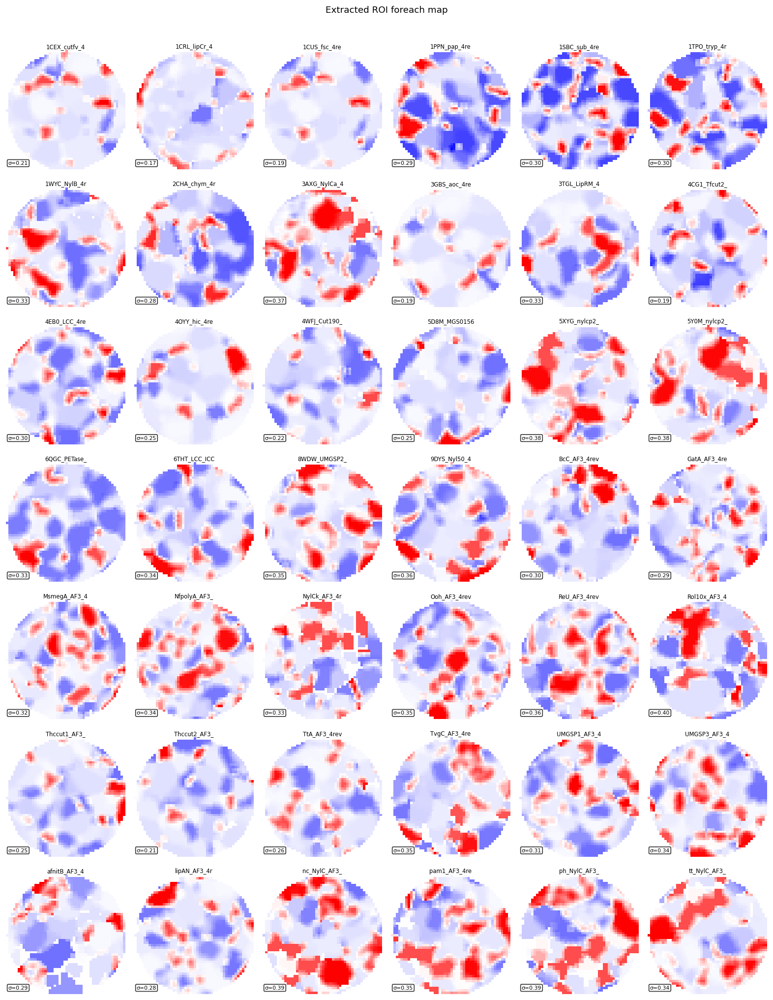

In [8]:
def plot_roi_closeups(npy_files, map_names, circle_mask,
                       roi_radius=ROI_RADIUS, h=MAP_HEIGHT, w=MAP_WIDTH, n_cols=6):
    N = len(npy_files)
    n_rows = (N + n_cols - 1) // n_cols
    cy, cx = h // 2, w // 2
    y0, y1 = max(0, cy - roi_radius), min(h, cy + roi_radius)
    x0, x1 = max(0, cx - roi_radius), min(w, cx + roi_radius)

    yy, xx = np.ogrid[y0:y1, x0:x1]
    local_circle = ((xx - cx)**2 + (yy - cy)**2) <= roi_radius**2

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 2.2, n_rows * 2.4))
    axes_flat = axes.flatten() if n_rows > 1 else list(axes) if n_cols > 1 else [axes]

    for idx, (fpath, name) in enumerate(zip(npy_files, map_names)):
        m = np.load(fpath)
        roi = m[y0:y1, x0:x1].astype(float)
        roi[~local_circle] = np.nan

        vmax = np.nanmax(np.abs(roi))
        if vmax == 0 or np.isnan(vmax):
            vmax = 1.0

        ax = axes_flat[idx]
        ax.imshow(roi, cmap='bwr_r', vmin=-vmax, vmax=vmax)
        ax.set_title(name[:12], fontsize=7, pad=2)
        ax.axis('off')

        gs = np.std(m[circle_mask])
        color = 'black'
        ax.text(0.02, 0.04, f"σ={gs:.2f}", transform=ax.transAxes,
                fontsize=6.5, color=color,
                bbox=dict(boxstyle='round,pad=0.2', fc='white', alpha=0.8))

    for j in range(idx + 1, len(axes_flat)):
        axes_flat[j].axis('off')

    plt.suptitle("Extracted ROI foreach map", fontsize=11, y=1.01)
    plt.tight_layout()
    plt.show()


plot_roi_closeups(npy_files, map_names, circle_mask)

## similarity matrix


In [9]:

scaler  = StandardScaler()
A_scaled = scaler.fit_transform(A_raw)
B_scaled = scaler.transform(B_raw.reshape(-1, V_FEATS)).reshape(N, SHIFTS, V_FEATS)

# L2-norm (cosine - iloczyn skalarny wektorów jednostkowych)
A_norm = A_scaled / np.clip(norm(A_scaled, axis=1, keepdims=True), 1e-9, None)
B_norm = B_scaled / np.clip(norm(B_scaled, axis=2, keepdims=True), 1e-9, None)

# global std for arg magnitudy
map_stds = np.array([np.std(np.load(f)[circle_mask]) for f in npy_files], dtype=np.float32)
print(f"std range ROI: {map_stds.min():.3f} – {map_stds.max():.3f}  |  median: {np.median(map_stds):.3f}")

sim_matrix = np.zeros((N, N), dtype=np.float32)
best_rot   = np.zeros((N, N), dtype=np.int32)
np.fill_diagonal(sim_matrix, 1.0)

alpha = 1.0 - MAGNITUDE_WEIGHT   # weight/cost cosinus

for i in tqdm(range(N), desc="similarity matrix:"):
    for j in range(i + 1, N):
        sims     = B_norm[j] @ A_norm[i]  # shape (SHIFTS,)
        best_idx = int(np.argmax(sims))
        cos_sim  = float(sims[best_idx])

        si, sj = map_stds[i], map_stds[j]
        if max(si, sj) < 1e-9:
            mag_sim = 1.0
        else:
            mag_sim = float(min(si, sj) / max(si, sj)) ##[0, 1]

        #combined measure
        combined = alpha * max(0.0, cos_sim) + MAGNITUDE_WEIGHT * mag_sim

        sim_matrix[i, j] = combined
        sim_matrix[j, i] = combined
        best_rot[i, j]   = best_idx * 2
        best_rot[j, i]   = (360 - best_idx * 2) % 360

upper = sim_matrix[np.triu_indices(N, 1)]
print(f"Median sim: {np.median(upper):.3f}")
print(f"max sim: {upper.max():.3f}")
print(f"Min. sim: {upper.min():.3f}")

std range ROI: 0.171 – 0.399  |  median: 0.315


similarity matrix::   0%|          | 0/42 [00:00<?, ?it/s]

Median sim: 0.469
max sim: 0.849
Min. sim: 0.150


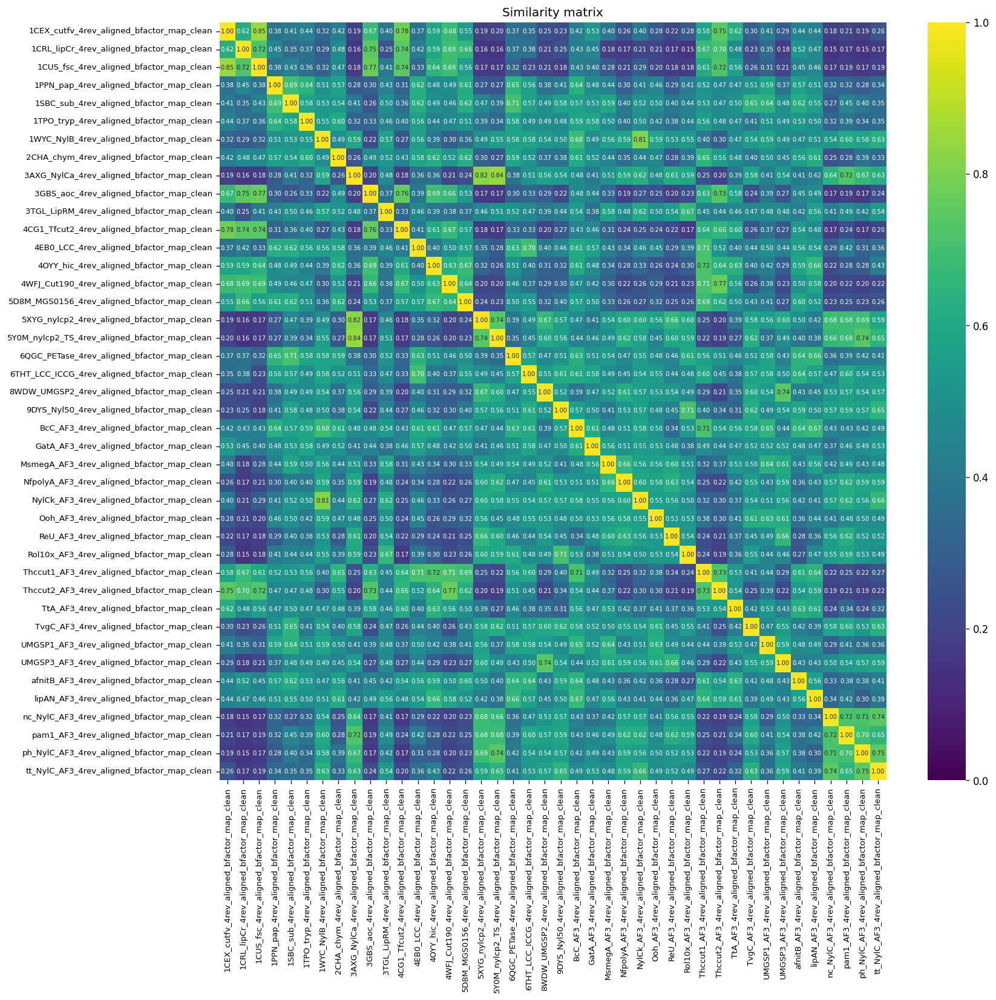

In [10]:
fig, ax = plt.subplots(figsize=(max(14, N * 0.35), max(12, N * 0.33)))

sns.heatmap(
    sim_matrix,
    annot=N <= 50,
    fmt=".2f",
    cmap='viridis',
    xticklabels=map_names,
    yticklabels=map_names,
    vmin=0, vmax=1,
    annot_kws={"size": 6},
    ax=ax
)
ax.set_xticklabels(ax.get_xticklabels(), rotation=90, fontsize=8)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0,  fontsize=8)
ax.set_title(f"Similarity matrix")
plt.tight_layout()
plt.show()

Nr PC to 90% variance: 22
 PC1: 18.6%
 PC2: 9.7%
 PC3: 7.8%


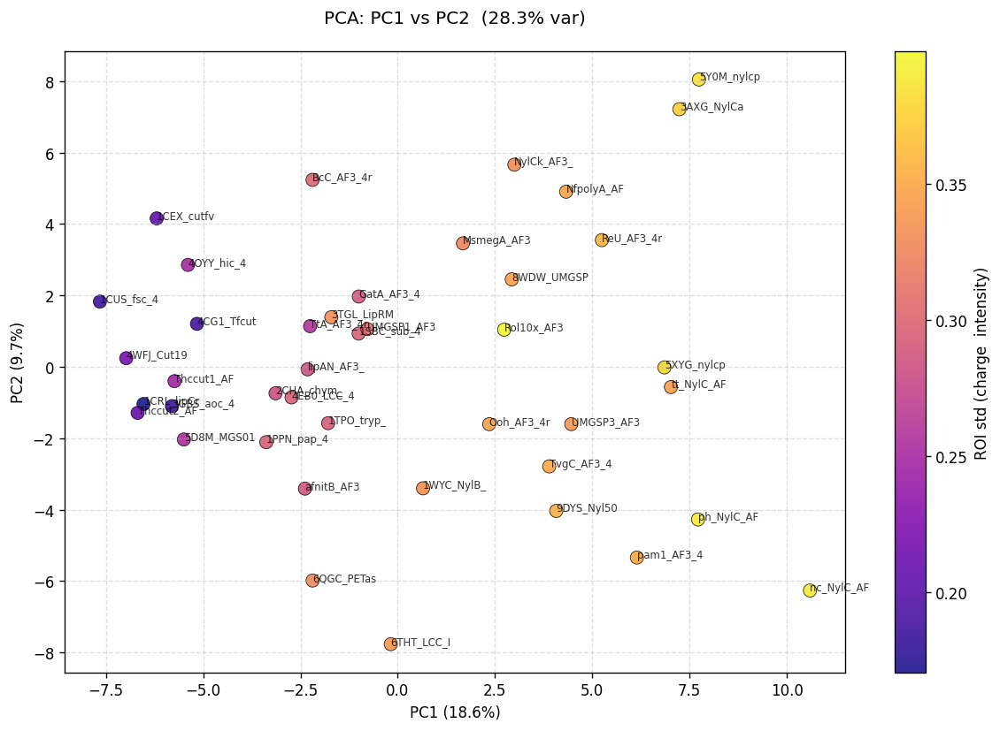

In [11]:
pca = PCA(n_components=0.90)
pca_feats = pca.fit_transform(A_scaled)

print(f"Nr PC to 90% variance: {pca.n_components_}")
for k in range(min(3, pca.n_components_)):
    print(f" PC{k+1}: {pca.explained_variance_ratio_[k]*100:.1f}%")

fig, ax = plt.subplots(figsize=(10, 7))
sc = ax.scatter(pca_feats[:, 0], pca_feats[:, 1],
                c=map_stds, cmap='plasma', s=80, alpha=0.85, edgecolor='k', linewidths=0.5)
plt.colorbar(sc, ax=ax, label='ROI std (charge  intensity)')
for i, txt in enumerate(map_names):
    ax.annotate(txt[:10], (pca_feats[i, 0], pca_feats[i, 1]), fontsize=7, alpha=0.8)
ax.set_title(
    f'PCA: PC1 vs PC2  ({np.sum(pca.explained_variance_ratio_[:2])*100:.1f}% var)\n'
)
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
ax.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

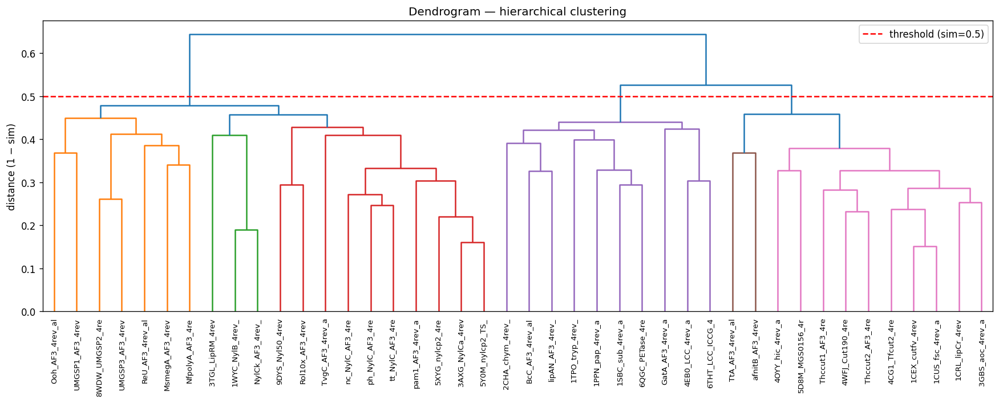

In [12]:
dist_matrix    = np.clip(1.0 - sim_matrix, 0, 1)
condensed_dist = squareform(dist_matrix, checks=False)
Z = linkage(condensed_dist, method='average')

plt.figure(figsize=(max(12, N * 0.35), 6))
dendrogram(Z, labels=[n[:15] for n in map_names], leaf_rotation=90, leaf_font_size=8)
plt.title("Dendrogram — hierarchical clustering")
plt.ylabel("distance (1 − sim)")
plt.axhline(y=1.0 - GRAPH_SIM_THRESHOLD, color='red', linestyle='--',
            label=f'threshold (sim={GRAPH_SIM_THRESHOLD})')
plt.legend()
plt.tight_layout()
plt.show()

labels_hier = fcluster(Z, t=1.0 - GRAPH_SIM_THRESHOLD, criterion='distance')

Louvain algorithm selected: 3 clusters.


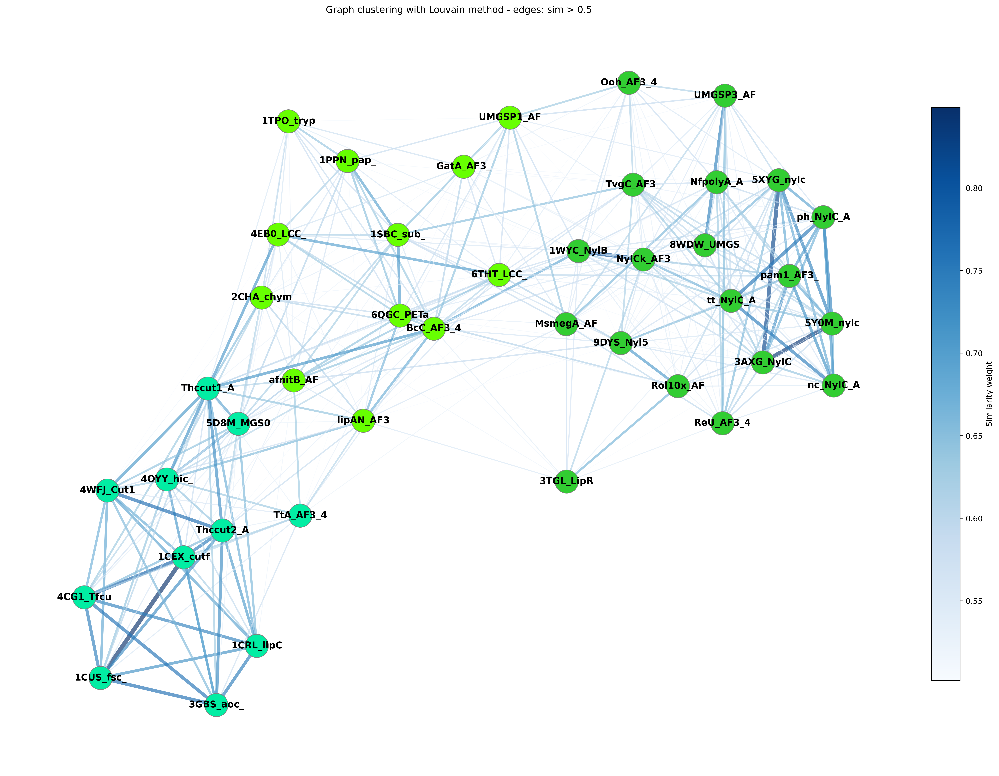

In [54]:

# print(f"threshold: {GRAPH_SIM_THRESHOLD} ")
# n_above = np.sum(sim_matrix[np.triu_indices(N, 1)] > GRAPH_SIM_THRESHOLD)
# print(f"pairs above threshold: {n_above} / {N*(N-1)//2}")

# G = nx.Graph()
# for i in range(N):
#     G.add_node(i, name=map_names[i])

# for i in range(N):
#     for j in range(i + 1, N):
#         if sim_matrix[i, j] > GRAPH_SIM_THRESHOLD:
#             G.add_edge(i, j, weight=float(sim_matrix[i, j]))

# partition = community_louvain.best_partition(G, weight='weight', random_state=42)
# clusters  = [partition.get(i, -1) for i in range(N)]
# n_clusters = len(set(clusters))
# print(f"Louvain algorithm select: {n_clusters} clusters.")

# fig, ax = plt.subplots(figsize=(13, 10))
# pos  = nx.spring_layout(G, seed=42, k=0.6)
# cmap = plt.cm.get_cmap('Set2', max(clusters) + 1)

# nx.draw_networkx_nodes(G, pos, ax=ax, node_size=350, cmap=cmap,
#                        node_color=clusters, edgecolors='grey', linewidths=0.8)
# nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.3, width=1.5, edge_color='#C2C2C2')
# nx.draw_networkx_labels(G, pos, {i: map_names[i][:9] for i in range(N)},
#                         font_size=10, ax=ax, font_weight='bold')
# ax.set_title(f"Graph clustering (Louvain) - edges: sim > {GRAPH_SIM_THRESHOLD}")
# ax.axis('off')
# plt.tight_layout()
# plt.show()

from matplotlib.colors import LinearSegmentedColormap

edge_cmap = LinearSegmentedColormap.from_list(
    "custom_edges",
    [
        "#87bfff",
        "#3f8efc",
        "#2667ff"
    ]
)

G = nx.Graph()
for i in range(N):
    G.add_node(i, name=map_names[i])

for i in range(N):
    for j in range(i + 1, N):
        w = float(sim_matrix[i, j])
        if w > GRAPH_SIM_THRESHOLD:
            G.add_edge(i, j, weight=w)

partition = community_louvain.best_partition(G, weight='weight', random_state=42)
clusters = [partition.get(i, -1) for i in range(N)]
n_clusters = len(set(clusters))
print(f"Louvain algorithm selected: {n_clusters} clusters.")

custom_cluster_colors = ["#02eda3", "#67ff01", "#32cd32"]

node_colors = [
    custom_cluster_colors[c % len(custom_cluster_colors)]
    for c in clusters
]

fig, ax = plt.subplots(figsize=(18, 14), dpi=400)

pos = nx.spring_layout(G, seed=42, k=0.6, weight='weight')

nx.draw_networkx_nodes(
    G, pos, ax=ax, node_size=900,
    node_color=node_colors,
    edgecolors='grey', linewidths=0.8
)

weights = np.array([G[u][v]['weight'] for u, v in G.edges()])
if len(weights) > 0:
    w_min, w_max = weights.min(), weights.max()
    norm = mpl.colors.Normalize(vmin=w_min, vmax=w_max)
    edge_cmap = plt.cm.Blues
    widths = 0.5 + 5.0 * (weights - w_min) / (w_max - w_min + 1e-12)

    nx.draw_networkx_edges(
        G, pos,
        edge_color=weights,
        edge_cmap=edge_cmap,
        edge_vmin=w_min,
        edge_vmax=w_max,
        width=widths,
        alpha=0.65
    )

    sm = mpl.cm.ScalarMappable(cmap=edge_cmap, norm=norm)
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax, fraction=0.03, pad=0.02)
    cbar.set_label('Similarity weight')
else:
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.3, width=1.5, edge_color='#C2C2C2')

nx.draw_networkx_labels(
    G, pos, {i: map_names[i][:9] for i in range(N)},
    font_size=12, ax=ax, font_weight='bold'
)

ax.set_title(f"Graph clustering with Louvain method - edges: sim > {GRAPH_SIM_THRESHOLD}")
ax.axis('off')

plt.tight_layout()
plt.savefig("graph.png", dpi=400, bbox_inches="tight")
plt.show()

## clusters vis



 Cluster 0  (11 maps) 


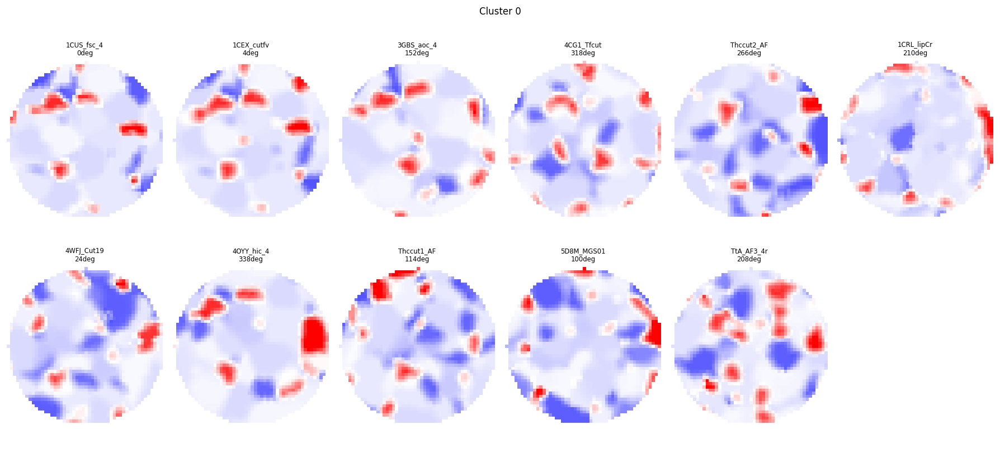


 Cluster 1  (12 maps) 


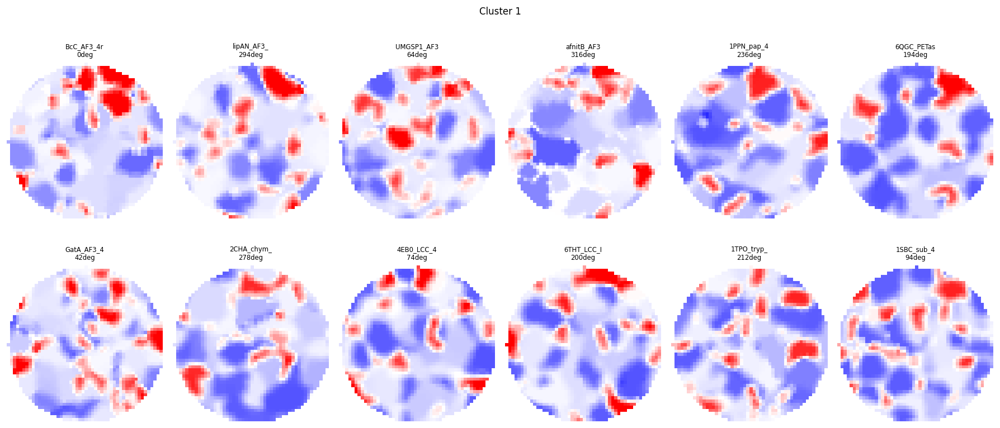


 Cluster 2  (19 maps) 


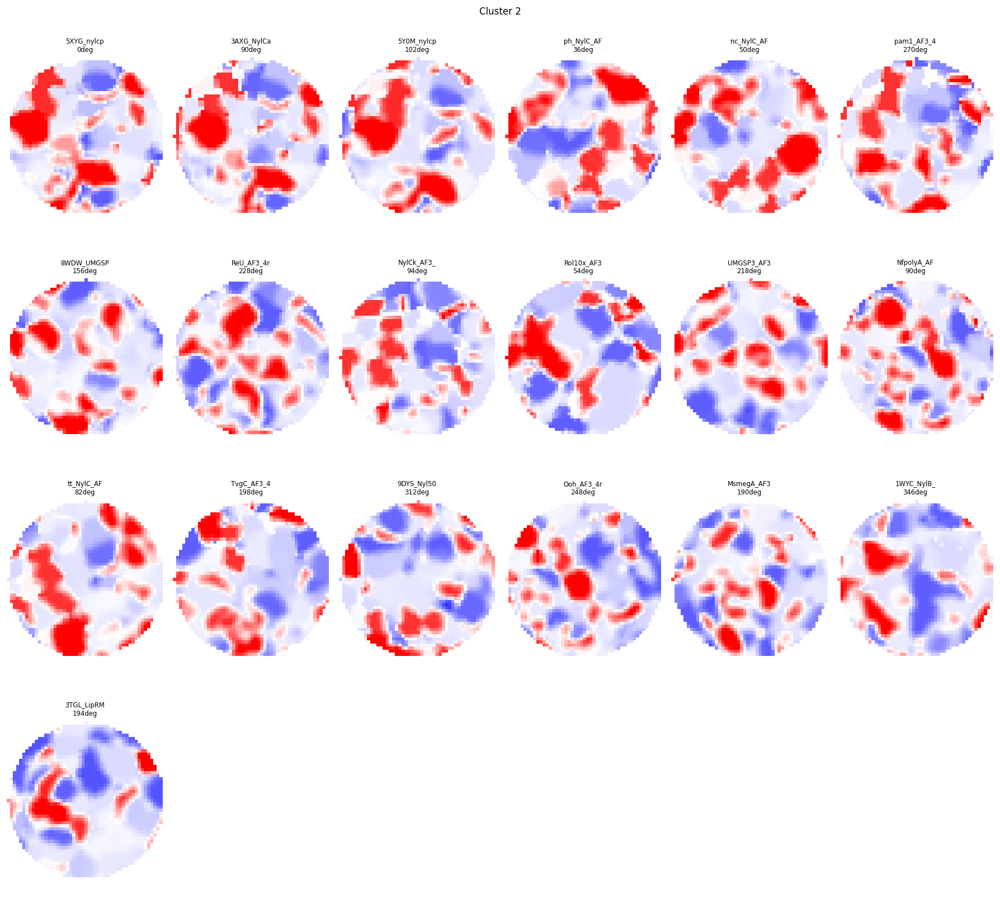

In [48]:

def apply_circle_nan_mask(patch, radius=ROI_RADIUS):
    ph, pw = patch.shape
    cy, cx = ph // 2, pw // 2
    yy, xx = np.ogrid[:ph, :pw]
    p = patch.copy()
    p[((xx - cx)**2 + (yy - cy)**2) > radius**2] = np.nan
    return p


def extract_roi_image(m, radius=ROI_RADIUS, h=MAP_HEIGHT, w=MAP_WIDTH):
    patch = extract_roi_patch(m, radius, h, w)
    return apply_circle_nan_mask(patch, radius)


def extract_roi_image_rotated(m, angle_deg, radius=ROI_RADIUS, h=MAP_HEIGHT, w=MAP_WIDTH):
    patch = extract_roi_patch(m, radius, h, w)
    if angle_deg == 0:
        return apply_circle_nan_mask(patch, radius)
    patch_rot = ndimage_rotate(patch, angle_deg, reshape=False,
                               mode='nearest', order=1)
    return apply_circle_nan_mask(patch_rot, radius)


def best_ref_in_cluster(idxs, sim_matrix):
    if len(idxs) == 1:
        return idxs[0]
    mean_sims = [
        np.mean([sim_matrix[i, j] for j in idxs if j != i])
        for i in idxs
    ]
    return idxs[int(np.argmax(mean_sims))]


unique_clusters = sorted(set(clusters))

global_vmax = np.percentile(np.abs(np.concatenate(
    [np.load(f)[circle_mask] for f in npy_files]
)), 97)

for cid in unique_clusters:
    idxs = [i for i, c in enumerate(clusters) if c == cid]
    stds_in_cluster = [map_stds[i] for i in idxs]

    ref_idx = best_ref_in_cluster(idxs, sim_matrix)

    others = sorted([i for i in idxs if i != ref_idx],
                    key=lambda x: sim_matrix[ref_idx, x], reverse=True)
    ordered_idxs = [ref_idx] + others

    n_show = len(ordered_idxs)
    print(f"\n Cluster {cid}  ({n_show} maps) ")

    n_cols = min(n_show, 6)
    n_rows = (n_show + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 2.5, n_rows * 3.5))

    if n_rows == 1 and n_cols == 1:
        axes = [axes]
    elif isinstance(axes, np.ndarray):
        axes = axes.flatten()

    for ax_idx, map_idx in enumerate(ordered_idxs):
        m_orig = np.load(npy_files[map_idx])

        if map_idx == ref_idx:
            roi = extract_roi_image(m_orig)
            rot_deg  = 0
            is_ref   = True
        else:
            rot_deg = int(best_rot[ref_idx, map_idx])
            roi = extract_roi_image_rotated(m_orig, rot_deg)
            is_ref  = False

        ax = axes[ax_idx]
        ax.imshow(roi, cmap='bwr_r', vmin=-global_vmax, vmax=global_vmax)

        for spine in ax.spines.values():
            spine.set_edgecolor('gold')
            spine.set_linewidth(3)
            spine.set_visible(True)
        rot_label = f"{rot_deg}deg"

        ax.set_title(
            f"{map_names[map_idx][:10]}\n"
            f"{rot_label}",
            fontsize=7, color='black'
        )
        ax.axis('off')

    for blank_ax in axes[n_show:]:
        blank_ax.axis('off')

    plt.suptitle(
        f"Cluster {cid}",
        fontsize=10, y=0.98
    )
    plt.tight_layout()
    plt.show()


## similar pairs  summary


In [53]:
rows = []
for i in range(N):
    for j in range(i + 1, N):
        rows.append({
            'Maps A':     map_names[i],
            'Maps B':     map_names[j],
            'Similarity': round(float(sim_matrix[i, j]), 3),
            'std_A':        round(float(map_stds[i]), 3),
            'std_B':        round(float(map_stds[j]), 3),
            'Cluster A':  clusters[i],
            'Cluster B':  clusters[j],
            # 'Same cluster in  different method?': clusters[i] == clusters[j]
        })

df_pairs = pd.DataFrame(rows).sort_values('Similarity', ascending=False)

print("TOP20:")
display(df_pairs.head(20))

print("\nWORST20:")
df_pairs2 = pd.DataFrame(rows).sort_values('Similarity', ascending=True)
display(df_pairs2.head(20))

TOP20:


,Maps A,Maps B,Similarity,std_A,std_B,Cluster A,Cluster B
1,1CEX_cutfv_4rev_aligned_bfactor_map_clean,1CUS_fsc_4rev_aligned_bfactor_map_clean,0.849,0.206,0.187,0,0
308,3AXG_NylCa_4rev_aligned_bfactor_map_clean,5Y0M_nylcp2_TS_4rev_aligned_bfactor_map_clean,0.840,0.374,0.385,2,2
307,3AXG_NylCa_4rev_aligned_bfactor_map_clean,5XYG_nylcp2_4rev_aligned_bfactor_map_clean,0.821,0.374,0.376,2,2
250,1WYC_NylB_4rev_aligned_bfactor_map_clean,NylCk_AF3_4rev_aligned_bfactor_map_clean,0.811,0.334,0.332,2,2
10,1CEX_cutfv_4rev_aligned_bfactor_map_clean,4CG1_Tfcut2_4rev_aligned_bfactor_map_clean,0.781,0.206,0.190,0,0
499,4WFJ_Cut190_4rev_aligned_bfactor_map_clean,Thccut2_AF3_4rev_aligned_bfactor_map_clean,0.768,0.220,0.212,0,0
87,1CUS_fsc_4rev_aligned_bfactor_map_clean,3GBS_aoc_4rev_aligned_bfactor_map_clean,0.766,0.187,0.186,0,0
334,3GBS_aoc_4rev_aligned_bfactor_map_clean,4CG1_Tfcut2_4rev_aligned_bfactor_map_clean,0.761,0.186,0.190,0,0
860,ph_NylC_AF3_4rev_aligned_bfactor_map_clean,tt_NylC_AF3_4rev_aligned_bfactor_map_clean,0.753,0.390,0.344,2,2
30,1CEX_cutfv_4rev_aligned_bfactor_map_clean,Thccut2_AF3_4rev_aligned_bfactor_map_clean,0.748,0.206,0.212,0,0



WORST20:


,Maps A,Maps B,Similarity,std_A,std_B,Cluster A,Cluster B
68,1CRL_lipCr_4rev_aligned_bfactor_map_clean,Rol10x_AF3_4rev_aligned_bfactor_map_clean,0.150,0.171,0.399,0,2
77,1CRL_lipCr_4rev_aligned_bfactor_map_clean,nc_NylC_AF3_4rev_aligned_bfactor_map_clean,0.153,0.171,0.390,0,2
79,1CRL_lipCr_4rev_aligned_bfactor_map_clean,ph_NylC_AF3_4rev_aligned_bfactor_map_clean,0.153,0.171,0.390,0,2
56,1CRL_lipCr_4rev_aligned_bfactor_map_clean,5Y0M_nylcp2_TS_4rev_aligned_bfactor_map_clean,0.155,0.171,0.385,0,2
55,1CRL_lipCr_4rev_aligned_bfactor_map_clean,5XYG_nylcp2_4rev_aligned_bfactor_map_clean,0.159,0.171,0.376,0,2
47,1CRL_lipCr_4rev_aligned_bfactor_map_clean,3AXG_NylCa_4rev_aligned_bfactor_map_clean,0.160,0.171,0.374,0,2
361,3GBS_aoc_4rev_aligned_bfactor_map_clean,nc_NylC_AF3_4rev_aligned_bfactor_map_clean,0.167,0.186,0.390,0,2
67,1CRL_lipCr_4rev_aligned_bfactor_map_clean,ReU_AF3_4rev_aligned_bfactor_map_clean,0.167,0.171,0.359,0,2
363,3GBS_aoc_4rev_aligned_bfactor_map_clean,ph_NylC_AF3_4rev_aligned_bfactor_map_clean,0.167,0.186,0.390,0,2
413,4CG1_Tfcut2_4rev_aligned_bfactor_map_clean,Rol10x_AF3_4rev_aligned_bfactor_map_clean,0.167,0.190,0.399,0,2
